# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** Вариант NLP. Устройство: cpu. Модель [RuBERT-tiny2](https://huggingface.co/cointegrated/rubert-tiny2) (MIT, ревизия `e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae`). Датасет: [WikiNEuRal](https://huggingface.co/datasets/Babelscape/wikineural), русские сплиты, CC BY-NC-SA 4.0. Бонусы не выбраны. Источники: шаблон ДЗ, карточки модели и датасета, документация Transformers. Код подготовлен с помощью Codex. Полный последовательный прогон с `FAST_MODE=False` завершён, результаты сохранены в ноутбуке и `artifacts/metrics.json`.

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

/opt/hostedtoolcache/Python/3.13.18/x64/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.15.0+cpu, transformers 5.22.1, datasets 5.1.0
CUDA available: False


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cpu cpu


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = set()   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'cointegrated/rubert-tiny2'
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'
TOKENIZER_KWARGS = {}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}


BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** RuBERT-tiny2 (около 29 млн параметров, MIT) ориентирован на русский язык. Он меньше многоязычного mBERT (около 180 млн), поэтому удобнее для полного дообучения на одной GPU. У его предшественника RuBERT-tiny примерно 12 млн параметров и словарь на 29 564 токена против 83 828 у tiny2. Более крупный словарь может помочь реже дробить русские названия. Точный хеш закрепляет веса, конфигурацию и токенизатор. [Карточка модели](https://huggingface.co/cointegrated/rubert-tiny2).

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 10522.99it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    base = model.base_model
    def count(module):
        return sum(p.numel() for p in module.parameters())
    embeddings = count(base.embeddings)
    layers = [count(layer) for layer in base.encoder.layer]
    head = count(model.classifier)
    encoder = sum(layers)
    return dict(embeddings=embeddings, encoder=encoder, head=head,
                other=count(model) - embeddings - encoder - head, layers=layers)

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
with torch.inference_mode():
    out = demo_model.eval()(**enc, output_hidden_states=True)
print('input_ids', enc['input_ids'].shape, 'attention_mask', enc['attention_mask'].shape)
print('hidden_states', [tuple(h.shape) for h in out.hidden_states])
print('logits', out.logits.shape)

input_ids torch.Size([2, 11]) attention_mask torch.Size([2, 11])
hidden_states [(2, 11, 312), (2, 11, 312), (2, 11, 312), (2, 11, 312)]
logits torch.Size([2, 11, 7])


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 38.6 ms на cpu


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** Эмбеддинги переводят (B, T) ID в (B, T, H). На демо формы состояний [(2, 11, 312), (2, 11, 312), (2, 11, 312), (2, 11, 312)], логиты torch.Size([2, 11, 7]). Контекст передаётся между токенами в энкодере, а линейная голова независимо применяет одни и те же веса к каждой позиции. Длину T задают сабворды, специальные токены и padding. Большая таблица эмбеддингов занимает основную долю параметров у этой модели.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating validation split: 100%|██████████| 10000/10000 [00:00<00:00, 991326.87 examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split: 100%|██████████| 10000/10000 [00:00<00:00, 1336191.14 examples/s]

Generating train split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Generating train split: 100%|██████████| 20000/20000 [00:00<00:00, 1709483.81 examples/s]

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
DATASET_ID, DATASET_CONFIG = 'Babelscape/wikineural', None
raw = DatasetDict({split: load_dataset(DATASET_ID, split=source)
                   for split, source in [('train', 'train_ru'), ('validation', 'val_ru'), ('test', 'test_ru')]})
# WikiNEuRal хранит ID как int. Порядок взят из карточки датасета.
LABEL_NAMES = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
print(raw)
print('Теги:', LABEL_NAMES)

Generating test_de split:   0%|          | 0/12372 [00:00<?, ? examples/s]

Generating test_de split: 100%|██████████| 12372/12372 [00:00<00:00, 875887.06 examples/s]

Generating test_en split:   0%|          | 0/11597 [00:00<?, ? examples/s]

Generating test_en split: 100%|██████████| 11597/11597 [00:00<00:00, 935374.48 examples/s]

Generating test_es split:   0%|          | 0/9618 [00:00<?, ? examples/s]

Generating test_es split: 100%|██████████| 9618/9618 [00:00<00:00, 848226.75 examples/s]

... (45 outputs left out)

Generating val_pt split: 100%|██████████| 10070/10070 [00:00<00:00, 913837.19 examples/s]

Generating val_ru split:   0%|          | 0/11540 [00:00<?, ? examples/s]

Generating val_ru split: 100%|██████████| 11540/11540 [00:00<00:00, 1005782.32 examples/s]

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 92320
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 11540
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 11580
    })
})
Теги: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']


In [14]:
# Готовая разметка уже в BIO. Статистика считается в 2.2 вместе с переводом в спаны.

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** WikiNEuRal автоматически размечает тексты Википедии, лицензия CC BY-NC-SA 4.0. train — 92,320 предложений (LOC 71,090, MISC 23,594, ORG 20,236, PER 33,282). validation — 11,540 предложений (LOC 8,851, MISC 2,642, ORG 2,710, PER 4,007). test — 11,580 предложений (LOC 8,596, MISC 2,962, ORG 3,051, PER 3,489). В validation реже всего MISC. В train медиана длины предложения 17 слов, 95-й процентиль 41, однословных сущностей 116,812. Длинные спаны повышают риск ошибки границы, а в автоматической разметке возможны пропуски. [Карточка корпуса](https://huggingface.co/datasets/Babelscape/wikineural).

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    spans, active = [], None
    for pos, tag in enumerate([*tags, 'O']):
        if tag != 'O':
            prefix, kind = tag.split('-', 1)
            if prefix == 'I' and active == kind:
                continue
        if active is not None:
            spans.append((start, pos, active))
        active = None if tag == 'O' else kind
        start = pos
    return spans


def spans_to_bio(spans, n_words):
    tags = ['O'] * n_words
    for start, end, kind in spans:
        tags[start:end] = ['B-' + kind] + ['I-' + kind] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    labels, previous = [], None
    for word in word_ids:
        if word is None:
            label = -100
        elif word != previous:
            label = word_labels[word]
        elif b_to_i is None:
            label = -100
        else:
            label = b_to_i.get(word_labels[word], word_labels[word])
        labels.append(label)
        previous = word
    return labels

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
Path('data').mkdir(exist_ok=True)
stats = {}
for split, rows in raw.items():
    path = Path('data') / f'{split}_spans.jsonl'
    counts, lengths = collections.Counter(), collections.Counter()
    sentence_lengths = []
    with path.open('w', encoding='utf-8') as file:
        for row in rows:
            spans = bio_to_spans([LABEL_NAMES[i] for i in row['ner_tags']])
            counts.update(kind for _, _, kind in spans)
            lengths.update(end - start for start, end, _ in spans)
            sentence_lengths.append(len(row['tokens']))
            file.write(json.dumps(dict(tokens=row['tokens'], spans=spans), ensure_ascii=False) + '\n')
    normalized = 0
    with path.open(encoding='utf-8') as file:
        for row, line in zip(rows, file, strict=True):
            record = json.loads(line)
            assert record['tokens'] == row['tokens']
            tags = [LABEL_NAMES[i] for i in row['ner_tags']]
            restored = spans_to_bio(record['spans'], len(tags))
            assert bio_to_spans(tags) == bio_to_spans(restored)
            normalized += tags != restored
    stats[split] = dict(rows=len(rows), types=dict(counts), span_lengths=dict(lengths),
                        words_p50=float(np.median(sentence_lengths)), words_p95=float(np.percentile(sentence_lengths, 95)),
                        words_max=max(sentence_lengths), normalized_bio=normalized)
    print(split, stats[split])

train {'rows': 92320, 'types': {'LOC': 71090, 'PER': 33282, 'MISC': 23594, 'ORG': 20236}, 'span_lengths': {1: 116812, 2: 21879, 3: 6566, 5: 599, 4: 1737, 6: 294, 7: 147, 10: 21, 12: 3, 8: 75, 9: 54, 17: 1, 11: 10, 18: 1, 13: 2, 24: 1}, 'words_p50': 17.0, 'words_p95': 41.0, 'words_max': 256, 'normalized_bio': 3210}


validation {'rows': 11540, 'types': {'ORG': 2710, 'LOC': 8851, 'MISC': 2642, 'PER': 4007}, 'span_lengths': {1: 14212, 2: 2789, 3: 858, 5: 73, 4: 210, 7: 20, 6: 35, 8: 10, 10: 1, 9: 2}, 'words_p50': 17.0, 'words_p95': 38.0, 'words_max': 107, 'normalized_bio': 393}


test {'rows': 11580, 'types': {'LOC': 8596, 'PER': 3489, 'MISC': 2962, 'ORG': 3051}, 'span_lengths': {1: 13829, 2: 2899, 4: 239, 6: 50, 3: 941, 8: 10, 5: 92, 13: 1, 7: 27, 10: 2, 9: 4, 11: 4}, 'words_p50': 17.0, 'words_p95': 38.0, 'words_max': 124, 'normalized_bio': 464}


In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/92320 [00:00<?, ? examples/s]

Map:   4%|▍         | 4000/92320 [00:00<00:03, 25393.82 examples/s]

Map:   9%|▊         | 8000/92320 [00:00<00:03, 26227.01 examples/s]

Map:  13%|█▎        | 12000/92320 [00:00<00:03, 26518.49 examples/s]

Map:  17%|█▋        | 16000/92320 [00:00<00:02, 26692.84 examples/s]

Map:  22%|██▏       | 20000/92320 [00:00<00:02, 26952.84 examples/s]

... (27 outputs left out)

Map: 100%|██████████| 11580/11580 [00:00<00:00, 27949.25 examples/s]

Map: 100%|██████████| 11580/11580 [00:00<00:00, 27761.64 examples/s]

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 92320
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 11540
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 11580
    })
})
ENTITY_TYPES ['LOC', 'MISC', 'ORG', 'PER']


train: проверено 92236 предложений, обрезано по MAX_LENGTH 83, слов без сабвордов или за обрезкой 2196
[CLS]            None  -100
Детство             0  O
провёл              1  O
в                   2  O
Над                 3  B-LOC
##ь                 3  -100
##сом               3  -100
##бат               3  -100
##е                 3  -100
,                   4  O
с                   5  O
1860                6  O
г                   7  O
.                   8  O
[SEP]            None  -100


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Слово может разбиться на несколько сабвордов. Ставлю метку на первый, чтобы длинные слова не получали больший вес. Остальные части слова и служебные токены имеют метку `-100`, которую loss пропускает. В train 83 предложения достигли лимита в 128 сабвордов. При токенизации и обрезке в сумме пропущено 2196 слов. При предсказании они получают `O`, из-за чего часть сущностей может пропасть или получить неверные границы. В 4067 предложениях исходные BIO-теги изменились после обратного перевода. Проверка подтвердила, что набор спанов сохранился во всех сплитах.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for word, tag in zip(words, tags):
            counts[word][tag] += 1
    return {word: tags.most_common(1)[0][0] for word, tags in counts.items()}


def predict_majority(tagger, words):
    return [tagger.get(word, 'O') for word in words]

In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

baseline = {}   # ваш код: baseline['majority'] и baseline['random_head'] - словари entity_scores

train_tags = [[LABEL_NAMES[i] for i in row] for row in data['train']['ner_tags']]
tagger = fit_majority_tagger(data['train']['tokens'], train_tags)
set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
baseline = dict(majority=entity_scores(val_gold, [predict_majority(tagger, words) for words in val_tokens]),
                random_head=entity_scores(val_gold, random_pred))
random_tag_counts = collections.Counter(tag for tags in random_pred for tag in tags)
print(baseline)
print('Частые теги случайной головы:', random_tag_counts.most_common(3))
del random_model

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 8875.24it/s]

{'majority': {'f1_micro': np.float64(0.5843722774656773), 'f1_macro': np.float64(0.5089478842707436), 'precision': np.float64(0.6450885454666048), 'recall': np.float64(0.5341021416803954)}, 'random_head': {'f1_micro': np.float64(0.029393424222334538), 'f1_macro': np.float64(0.028270139891322568), 'precision': np.float64(0.016691889635223688), 'recall': np.float64(0.12295442064799561)}}
Частые теги случайной головы: [('I-PER', 53044), ('O', 46258), ('B-PER', 38401)]


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** Словарь получил micro-F1 0.584 на validation. В Википедии названия повторяются, поэтому он часто угадывает метку по знакомому слову. Незнакомому слову словарь ставит `O`, а для знакомого берёт наиболее частый тег без учёта контекста. У случайной головы micro-F1 0.029. Она чаще всего выдавала `I-PER`, `O` и `B-PER`. Энкодер уже строит контекстные представления, но случайная голова ещё не связывает их с нужными тегами.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
LR = 2e-4
BATCH_SIZE = 32


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    tok = tok or tokenizer
    model.base_model.requires_grad_(not freeze_encoder)
    model.classifier.requires_grad_(True)
    steps = epochs * math.ceil(len(train_ds) / batch_size)
    interval = max(1, steps // 10)
    args = TrainingArguments(output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr,
                             per_device_train_batch_size=batch_size, per_device_eval_batch_size=64,
                             warmup_steps=int(0.06 * steps), weight_decay=0.01,
                             fp16=device.type == 'cuda', save_strategy='no', report_to=[],
                             eval_strategy='steps', logging_strategy='steps', eval_steps=interval,
                             logging_steps=interval, seed=SEED, disable_tqdm=True,
                             dataloader_pin_memory=device.type == 'cuda')
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok), processing_class=tok)
    start = time.perf_counter()
    trainer.train()
    return trainer.state.log_history, time.perf_counter() - start

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 10740.60it/s]

{'loss': '0.2481', 'grad_norm': '0.8381', 'learning_rate': '0.0001915', 'epoch': '0.2998'}


{'eval_loss': '0.08239', 'eval_runtime': '15.03', 'eval_samples_per_second': '767.8', 'eval_steps_per_second': '12.04', 'epoch': '0.2998'}


{'loss': '0.07783', 'grad_norm': '1.246', 'learning_rate': '0.0001703', 'epoch': '0.5997'}


{'eval_loss': '0.06963', 'eval_runtime': '16.58', 'eval_samples_per_second': '695.8', 'eval_steps_per_second': '10.91', 'epoch': '0.5997'}


... (13 outputs left out)

{'eval_loss': '0.06838', 'eval_runtime': '15.14', 'eval_samples_per_second': '762', 'eval_steps_per_second': '11.95', 'epoch': '2.698'}


{'loss': '0.01835', 'grad_norm': '0.06453', 'learning_rate': '1.475e-07', 'epoch': '2.998'}


{'eval_loss': '0.06798', 'eval_runtime': '15.48', 'eval_samples_per_second': '745.7', 'eval_steps_per_second': '11.7', 'epoch': '2.998'}


{'eval_loss': '0.06798', 'eval_runtime': '15.47', 'eval_samples_per_second': '745.8', 'eval_steps_per_second': '11.7', 'epoch': '3'}
{'train_runtime': '2621', 'train_samples_per_second': '105.7', 'train_steps_per_second': '3.303', 'train_loss': '0.06078', 'epoch': '3'}
обучение: 2620.8 c на cpu, 92320 предложений, 3 эпох(а)


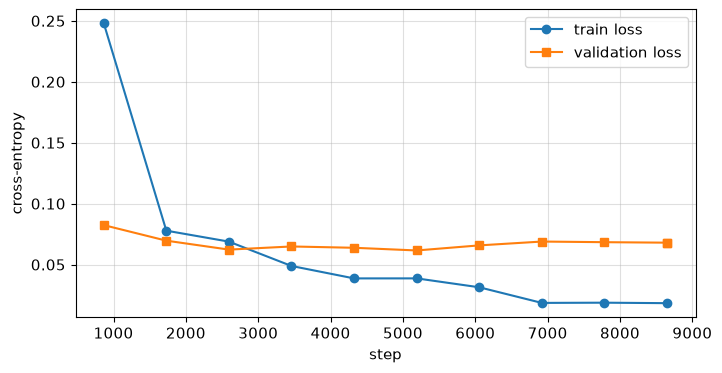

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** Я взял шаг 2e-4 для компактной модели, батч 32 и три эпохи, чтобы увидеть, как меняется loss. Warmup на 6% шагов сглаживает первые обновления, а weight decay 0.01 ограничивает рост весов. На CPU полное обучение заняло 43 мин 41 с. Validation loss достиг минимума 0.0616 примерно на 1.8-й эпохе, спустя 5190 шагов, и к концу вырос до 0.0680. Train loss при этом продолжал падать. Это похоже на начало переобучения. Больше эпох я бы пока не добавлял, сначала проверил бы раннюю остановку.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    actual = expected = matches = 0
    for a, b in zip(gold, pred):
        for g, p in zip(a, b):
            actual += p != 'O'
            expected += g != 'O'
            matches += p == g and g != 'O'
    return 2 * matches / (actual + expected) if actual + expected else 0.0

In [25]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

final = {}       # ваш код: метрики на test: f1_micro, f1_macro, precision, recall, token_f1, per_type
val_pred = []    # предсказанные теги validation (список списков), нужны в 5.1

test_tokens = list(data['test']['tokens'])
test_gold = [[LABEL_NAMES[i] for i in row] for row in data['test']['ner_tags']]
val_pred = predict_word_tags(model, val_tokens)
test_pred = predict_word_tags(model, test_tokens)
reports = {}
for split, gold_tags, predicted in [('validation', val_gold, val_pred), ('test', test_gold, test_pred)]:
    report = classification_report(gold_tags, predicted, output_dict=True, zero_division=0)
    reports[split] = dict(entity_scores(gold_tags, predicted), token_f1=token_f1(gold_tags, predicted),
                          per_type={kind: report[kind] for kind in ENTITY_TYPES if kind in report})
    print(split, reports[split])
final = dict(reports['test'], validation=reports['validation'])

validation {'f1_micro': np.float64(0.8600048996924082), 'f1_macro': np.float64(0.825225289687455), 'precision': np.float64(0.8526474874507476), 'recall': np.float64(0.8674903898956617), 'token_f1': 0.8699889627022637, 'per_type': {'LOC': {'precision': np.float64(0.9160382667416995), 'recall': np.float64(0.9195571121907129), 'f1-score': np.float64(0.9177943166441137), 'support': np.int64(8851)}, 'MISC': {'precision': np.float64(0.7280865348750466), 'recall': np.float64(0.7388342165026495), 'f1-score': np.float64(0.7334210031936876), 'support': np.int64(2642)}, 'ORG': {'precision': np.float64(0.7550877192982456), 'recall': np.float64(0.7940959409594096), 'f1-score': np.float64(0.7741007194244603), 'support': np.int64(2710)}, 'PER': {'precision': np.float64(0.8645098516176113), 'recall': np.float64(0.8869478412777639), 'f1-score': np.float64(0.8755851194875586), 'support': np.int64(4007)}}}


test {'f1_micro': np.float64(0.8607823305907115), 'f1_macro': np.float64(0.83134267042241), 'precision': np.float64(0.8517717067892886), 'recall': np.float64(0.8699856337716875), 'token_f1': 0.8734981468659634, 'per_type': {'LOC': {'precision': np.float64(0.923264736658528), 'recall': np.float64(0.9238017682643089), 'f1-score': np.float64(0.9235331743908821), 'support': np.int64(8596)}, 'MISC': {'precision': np.float64(0.7468099395567495), 'recall': np.float64(0.7508440243079001), 'f1-score': np.float64(0.7488215488215488), 'support': np.int64(2962)}, 'ORG': {'precision': np.float64(0.7416004886988393), 'recall': np.float64(0.7958046542117339), 'f1-score': np.float64(0.7677470355731225), 'support': np.int64(3051)}, 'PER': {'precision': np.float64(0.8678414096916299), 'recall': np.float64(0.9034107194038407), 'f1-score': np.float64(0.8852689229040865), 'support': np.int64(3489)}}}


**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** На validation micro-F1 по спанам 0.860. На test micro-F1 0.861, macro-F1 0.831, F1 по словам 0.873. Хуже всего распознаётся MISC (F1 0.749, support 2962). Разнообразие типа и частота могут влиять на это, но вклад причин отдельно не измерялся. Micro объединяет все сущности, macro усредняет классы с одинаковым весом. Разница между F1 по словам и F1 по спанам составляет +0.013. По словам можно получить частичный зачёт за правильно размеченную часть названия. Для извлечения сущностей ближе F1 по спанам, который требует обе границы и верный тип.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    def overlaps(a, b):
        return max(a[0], b[0]) < min(a[1], b[1])

    results = []
    for gold in gold_spans:
        overlapping = [p for p in pred_spans if overlaps(gold, p)]
        same_type = [p for p in overlapping if p[2] == gold[2]]
        if gold in overlapping:
            results.append(('correct', gold, gold))
        elif same_type:
            results.append(('boundary', gold, same_type[0]))
        elif overlapping:
            results.append(('type', gold, overlapping[0]))
        else:
            results.append(('missed', gold, None))
    for pred in pred_spans:
        if not any(overlaps(pred, gold) for gold in gold_spans):
            results.append(('spurious', None, pred))
    return results

In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

errors = {}   # ваш код: {категория: число} на validation, затем доли и 5+ примеров

errors = dict.fromkeys(ERROR_CATEGORIES, 0)
examples = collections.defaultdict(list)
for words, gold_tags, pred_tags in zip(val_tokens, val_gold, val_pred):
    for category, expected, actual in categorize_errors(bio_to_spans(gold_tags), bio_to_spans(pred_tags)):
        errors[category] += 1
        if category != 'correct' and len(examples[category]) < 2:
            examples[category].append((words, expected, actual))
total_errors = sum(errors[category] for category in ERROR_CATEGORIES[1:])
print('correct', errors['correct'])
for category in ERROR_CATEGORIES[1:]:
    print(f'{category}: {errors[category]} ({errors[category] / max(total_errors, 1):.1%})')
    for words, expected, actual in examples[category]:
        def describe(span):
            return (' '.join(words[span[0]:span[1]]) + f' ({span[2]})') if span else '—'
        print(' '.join(words), '| gold:', describe(expected), '| pred:', describe(actual))

correct 15797
boundary: 658 (22.0%)
Позднее , в 2001 г. , он вновь возьмётся за театральную роль в хите лондонского Вест-Энда " « Кошка на раскалённой крыше » " Теннесси Уильямса . | gold: Кошка на раскалённой крыше » (MISC) | pred: Кошка (MISC)
Позднее , в 2001 г. , он вновь возьмётся за театральную роль в хите лондонского Вест-Энда " « Кошка на раскалённой крыше » " Теннесси Уильямса . | gold: Теннесси Уильямса (PER) | pred: Уильямса (PER)
type: 1371 (45.7%)
С 1979 года на Украине лесосплав на реках запрещен , что закреплено в Водном кодексе Украины ( 1995 ) , ст . | gold: Украины (LOC) | pred: Водном кодексе Украины (MISC)
Героями мультсериала являются циничная девочка Мэнди , жизнерадостный дурачок Билли , и Смерть ( Грим ) . | gold: Смерть (MISC) | pred: Смерть (PER)
missed: 384 (12.8%)
Веспрем стал одной из первых епископских кафедр Венгрии , кафедра основана в 1009 году . | gold: Веспрем (LOC) | pred: —
Семейство Маревые выделяется в системе Кронквиста и многих других классифика

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** Чаще всего модель путала тип сущности: 1371 из 2997 ошибок (45.7%). В ошибках границы она выделяла только часть длинного названия или оставляла фамилию без имени. По типам путала, например, персонажа «Смерть» с именем человека. Из пропусков виден редкий топоним «Веспрем», а «Древнейшего» модель ошибочно выделила как место. Есть и спорные места в разметке: «Маревые» помечены как LOC, хотя в предложении это семейство растений. Чтобы уменьшить ошибки типа, сначала собрал бы самые частые пары перепутанных классов и вручную проверил эталон на таких примерах.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
ABLATION = 'freeze'
set_seed(SEED)
frozen = make_model()
_, frozen_seconds = train_ner(frozen, tokenized['train'], tokenized['validation'],
                              freeze_encoder=True, out_dir='runs/freeze')
frozen_pred = predict_word_tags(frozen, val_tokens)
ablations = [('full', model, val_pred, train_seconds), ('freeze', frozen, frozen_pred, frozen_seconds)]
ablation = dict(setting=ABLATION)
for name, candidate, preds, seconds in ablations:
    n_trainable = sum(p.numel() for p in candidate.parameters() if p.requires_grad)
    ablation[name] = dict(entity_scores(val_gold, preds), seconds=seconds, trainable_parameters=n_trainable)
print(ablation)
del ablations, frozen

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 11565.98it/s]

{'loss': '0.7558', 'grad_norm': '0.2514', 'learning_rate': '0.0001915', 'epoch': '0.2998'}


{'eval_loss': '0.2418', 'eval_runtime': '16.09', 'eval_samples_per_second': '717', 'eval_steps_per_second': '11.25', 'epoch': '0.2998'}


{'loss': '0.2208', 'grad_norm': '0.2472', 'learning_rate': '0.0001703', 'epoch': '0.5997'}


{'eval_loss': '0.1856', 'eval_runtime': '15.33', 'eval_samples_per_second': '752.6', 'eval_steps_per_second': '11.8', 'epoch': '0.5997'}


... (14 outputs left out)

{'loss': '0.1681', 'grad_norm': '0.1292', 'learning_rate': '1.475e-07', 'epoch': '2.998'}


{'eval_loss': '0.1488', 'eval_runtime': '16.06', 'eval_samples_per_second': '718.4', 'eval_steps_per_second': '11.27', 'epoch': '2.998'}


{'eval_loss': '0.1488', 'eval_runtime': '15.76', 'eval_samples_per_second': '732.3', 'eval_steps_per_second': '11.48', 'epoch': '3'}
{'train_runtime': '1196', 'train_samples_per_second': '231.6', 'train_steps_per_second': '7.236', 'train_loss': '0.2359', 'epoch': '3'}


{'setting': 'freeze', 'full': {'f1_micro': np.float64(0.8600048996924082), 'f1_macro': np.float64(0.825225289687455), 'precision': np.float64(0.8526474874507476), 'recall': np.float64(0.8674903898956617), 'seconds': 2620.7920324039997, 'trainable_parameters': 29098929}, 'freeze': {'f1_micro': np.float64(0.6328598259397402), 'f1_macro': np.float64(0.5378590214531423), 'precision': np.float64(0.6105241667942632), 'recall': np.float64(0.656891817682592), 'seconds': 1196.2570680109998, 'trainable_parameters': 2817}}


**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** При полном дообучении micro-F1 на validation составил 0.860. Обучались 29 098 929 параметров, это заняло 43 мин 41 с. При заморозке энкодера F1 упал до 0.633. Обучались только 2817 параметров головы, это заняло 19 мин 56 с. Заморозка сократила время примерно в 2.2 раза, но F1 снизился на 0.227. Похоже, для этого корпуса важно подстроить и признаки энкодера. Для проверки я бы повторил сравнение с несколькими seed.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** Словарь получил validation micro-F1 0.584. Полное дообучение дало 0.860 на validation и 0.861 на test. На test macro-F1 составил 0.831, а F1 по словам — 0.873. Замороженный энкодер дал 0.633 на validation. Чаще всего на validation встречалась ошибка type. Результаты относятся к автоматически размеченной Википедии и одному запуску. В следующем эксперименте стоит проверить самые частые пары типов.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "Babelscape/wikineural", "classes": ["LOC", "MISC", "ORG", "PER"], "n_train": 92320, "n_val": 11540, "n_test": 11580, "params_total": 29098929, "ablation": {"setting": "freeze", "full": {"f1_micro": 0.8600048996924082, "f1_macro": 0.825225289687455, "precision": 0.8526474874507476, "recall": 0.8674903898956617, "seconds": 2620.7920324039997, "trainable_parameters": 29098929}, "freeze": {"f1_micro": 0.6328598259397402, "f1_macro": 0.5378590214531423, "precision": 0.610524166
final F1 micro 0.8608


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [30]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** Бонус не включён в текущий прогон.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
if '6.2' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** Бонус не включён в текущий прогон.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [32]:
if '6.3' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** Бонус не включён в текущий прогон.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if '6.4' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** Бонус не включён в текущий прогон.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

In [34]:
if '6.5' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** Бонус не включён в текущий прогон.

In [35]:
# Короткая сводка для численных ответов после запуска.
print('Устройство:', DEVICE_NAME)
print('Формы демо:', tuple(out.hidden_states[0].shape), tuple(out.logits.shape), 'параметры:', blocks)
print('BIO-нормализация:', {split: row['normalized_bio'] for split, row in stats.items()})
print('Проверка токенизации:', n_truncated, 'предложений достигли MAX_LENGTH,', n_lost_words, 'слов потеряно')
print('Validation F1, бейзлайны:', {name: row['f1_micro'] for name, row in baseline.items()})
best_step, best_loss = min(eval_curve, key=lambda row: row[1])
print(f'Обучение: {train_seconds:.0f} c, минимум validation loss {best_loss:.4f} на шаге {best_step}; '
      f'последний validation loss {eval_curve[-1][1]:.4f}')
print('Test:', final)
print('Самый слабый тип на test:', min(final['per_type'], key=lambda kind: final['per_type'][kind]['f1-score']))
print('Чаще всего на validation:', max(ERROR_CATEGORIES[1:], key=errors.get), errors)
print('Абляция:', ablation)

Устройство: cpu
Формы демо: (2, 11, 312) (2, 11, 7) параметры: {'embeddings': 26794560, 'encoder': 2301552, 'head': 2191, 'other': 0, 'layers': [767184, 767184, 767184]}
BIO-нормализация: {'train': 3210, 'validation': 393, 'test': 464}
Проверка токенизации: 83 предложений достигли MAX_LENGTH, 2196 слов потеряно
Validation F1, бейзлайны: {'majority': np.float64(0.5843722774656773), 'random_head': np.float64(0.029393424222334538)}
Обучение: 2621 c, минимум validation loss 0.0616 на шаге 5190; последний validation loss 0.0680
Test: {'f1_micro': np.float64(0.8607823305907115), 'f1_macro': np.float64(0.83134267042241), 'precision': np.float64(0.8517717067892886), 'recall': np.float64(0.8699856337716875), 'token_f1': 0.8734981468659634, 'per_type': {'LOC': {'precision': np.float64(0.923264736658528), 'recall': np.float64(0.9238017682643089), 'f1-score': np.float64(0.9235331743908821), 'support': np.int64(8596)}, 'MISC': {'precision': np.float64(0.7468099395567495), 'recall': np.float64(0.750